In [1]:
# Generic imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from tqdm.auto import tqdm
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification

#Parameters
#MIN_UPVOTES = 2
dimensions = [15,10]
COLUMNS = ["user", "subreddit", "upvotes", "date", "content", "translated", "translated_clean"]

In [2]:
designers_comments = pd.read_csv("designers.csv")
programmers_comments = pd.read_csv("programmers.csv")

print(f"Designers comments: {designers_comments.shape[0]}")
print(f"Programmers comments: {programmers_comments.shape[0]}")

Designers comments: 17856
Programmers comments: 18320


In [3]:
# https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest
#

model_path = f"cardiffnlp/twitter-roberta-base-sentiment-latest"
tokenizer = AutoTokenizer.from_pretrained(model_path)
tokenizer.model_max_length = 512
model = AutoModelForSequenceClassification.from_pretrained(model_path)
pipe = pipeline("sentiment-analysis",
                model = model,
                tokenizer = tokenizer,
                return_all_scores = True,
                truncation = True)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cuda:0


model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/pipelines/text_classification.py:111: UserWarning: `return_all_scores` is now deprecated,  if want a similar functionality use `top_k=None` instead of `return_all_scores=True` or `top_k=1` instead of `return_all_scores=False`.
  warnings.warn(


### Sentiment analysis for the whole time period on programmers and designers


In [4]:
def sentiment(df, column = "translated_clean"):
  df = df.copy()
  """
  if "upvotes" in df.columns:
    df = df[df["upvotes"] >= min_upvotes]
  """
  #df = df.reset_index(drop=True)

  df["sentiment"] = ""
  df["score"] = 0.0
  df["positive"] = 0.0
  df["neutral"] = 0.0
  df["negative"] = 0.0

  for i in tqdm(range(len(df))):
    text= df.loc[i, column]
    predictions = pipe(text)[0]

    max_score = 0
    max_label = ""
    for p in predictions:
      df.loc[i, p["label"]] = round(p["score"], 4)
      if p["score"] > max_score:
        max_score = p["score"]
        max_label = p["label"]

    df.loc[i, "sentiment"] = max_label

    df.loc[i, "score"] = (df.loc[i, "positive"] * 1 + df.loc[i, "neutral"] * 0 + df.loc[i, "negative"] * (-1))

  return df



In [5]:
df_designers_sentiment = sentiment(designers_comments[COLUMNS])
display(df_designers_sentiment)

#save in csv
df_designers_sentiment.to_csv(f"designers_sentiment.csv", index = False)

  0%|          | 0/17856 [00:00<?, ?it/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,user,subreddit,upvotes,date,content,translated,translated_clean,sentiment,score,positive,neutral,negative
0,u/moreexclamationmarks,Design,2,2020-09-04,I don't even think it's the top of the curve t...,I don't even think it's the top of the curve t...,i do not even think it be the top of the curve...,negative,-0.5787,0.0238,0.3737,0.6025
1,u/Glynn_a,Design,1,2020-11-23,You don’t really need to hand them anything ex...,You don’t really need to hand them anything ex...,you do not really need to hand they anything e...,neutral,0.2363,0.2919,0.6526,0.0556
2,u/madmanbumandangel,Design,1,2021-04-14,Motion design in the film /commercial busines...,Motion design in the film /commercial busines...,motion design in the film /commercial busine...,neutral,-0.1761,0.0805,0.6629,0.2566
3,u/rwbronco,Design,2,2021-07-20,I don't think you'll be losing your job to AI....,I don't think you'll be losing your job to AI....,i do not think you will be lose your job to ai...,negative,-0.6492,0.0454,0.2600,0.6946
4,u/brron,Design,17,2021-09-11,"These are great if you freelance or dabble, bu...","These are great if you freelance or dabble, bu...","these be great if you freelance or dabble , bu...",neutral,0.1196,0.2464,0.6267,0.1268
...,...,...,...,...,...,...,...,...,...,...,...,...
17851,rudawiedzma,graphic_design,6,2025-05-02,So you have a portfolio of 10 years worth of p...,So you have a portfolio of 10 years worth of p...,so you have a portfolio of 10 year worth of pr...,negative,-0.4836,0.0318,0.4528,0.5154
17852,nobodynadienessuno,graphic_design,1,2025-09-22,Unpaid internships are a class barrier. The ne...,Unpaid internships are a class barrier. The ne...,unpaid internship be a class barrier . the nep...,negative,-0.5450,0.0230,0.4090,0.5680
17853,gigaflipflop,graphic_design,3,2025-06-19,I have a Masters degree and it has come in han...,I have a Masters degree and it has come in han...,i have a masters degree and it have come in ha...,positive,0.8440,0.8518,0.1405,0.0078
17854,xhipsterectomyx,graphic_design,29,2025-07-26,![gif](giphy|3ohfFhG5VDtDTzQv2o|downsized)\n\n...,![gif](giphy|3ohfFhG5VDtDTzQv2o|downsized)\n\n...,! [ gif](giphy|3ohffhg5vdtdtzqv2o|downsize ) \...,neutral,0.2167,0.2765,0.6637,0.0598


In [6]:
df_programmers_sentiment = sentiment(programmers_comments[COLUMNS])
display(df_programmers_sentiment)

#save in csv
df_programmers_sentiment.to_csv(f"programmers_sentiment.csv", index = False)

  0%|          | 0/18320 [00:00<?, ?it/s]

,user,subreddit,upvotes,date,content,translated,translated_clean,sentiment,score,positive,neutral,negative
0,u/rd211x,coding,-3,2021-07-09,It cant physically just copy and paste code. I...,It cant physically just copy and paste code. I...,it can not physically just copy and paste code...,neutral,-0.0233,0.1968,0.5831,0.2201
1,u/Wolf_Popular,coding,14,2022-07-18,I think there is something to the argument tha...,I think there is something to the argument tha...,i think there be something to the argument tha...,negative,-0.6247,0.0257,0.3239,0.6504
2,u/joesb,coding,8,2022-11-03,What business don’t realize is that programmin...,What business don’t realize is that programmin...,what business do not realize be that programmi...,negative,-0.4771,0.0208,0.4812,0.4979
3,u/ejpusa,coding,-11,2022-12-06,Over 4 1/2 decades. You probably use some of m...,Over 4 1/2 decades. You probably use some of m...,over 4 1/2 decade . you probably use some of m...,positive,0.7247,0.7604,0.2038,0.0357
4,u/abrandis,coding,2,2022-12-12,"Liability is a straw man argument, I would con...","Liability is a straw man argument, I would con...","liability be a straw man argument , i would co...",negative,-0.6522,0.0243,0.2992,0.6765
...,...,...,...,...,...,...,...,...,...,...,...,...
18315,Repulsive_Role_7446,programming,21,2025-03-26,"This screams ""I just started programming and I...","This screams ""I just started programming and I...","this scream "" i just start program and i do no...",negative,-0.6350,0.0502,0.2646,0.6852
18316,ReDucTor,programming,1,2025-08-14,"The rant about security was cringe, he clearly...","The rant about security was cringe, he clearly...","the rant about security be cringe , he clearly...",negative,-0.7535,0.0180,0.2104,0.7715
18317,BoBoBearDev,programming,5,2025-07-21,"Wait, are we talking about careeradvice instea...","Wait, are we talking about careeradvice instea...","wait , be we talk about careeradvice instead o...",neutral,-0.2053,0.0162,0.7623,0.2215
18318,swivelhinges,programming,7,2025-04-04,It's how it always goes... the same story as w...,It's how it always goes... the same story as w...,it be how it always go ... the same story as w...,neutral,0.2234,0.3135,0.5964,0.0901


In [7]:
df_all_sentiment = pd.concat([df_programmers_sentiment, df_designers_sentiment], ignore_index = True)
display(df_all_sentiment)

#save in csv
df_all_sentiment.to_csv(f"all_sentiment.csv", index = False)

,user,subreddit,upvotes,date,content,translated,translated_clean,sentiment,score,positive,neutral,negative
0,u/rd211x,coding,-3,2021-07-09,It cant physically just copy and paste code. I...,It cant physically just copy and paste code. I...,it can not physically just copy and paste code...,neutral,-0.0233,0.1968,0.5831,0.2201
1,u/Wolf_Popular,coding,14,2022-07-18,I think there is something to the argument tha...,I think there is something to the argument tha...,i think there be something to the argument tha...,negative,-0.6247,0.0257,0.3239,0.6504
2,u/joesb,coding,8,2022-11-03,What business don’t realize is that programmin...,What business don’t realize is that programmin...,what business do not realize be that programmi...,negative,-0.4771,0.0208,0.4812,0.4979
3,u/ejpusa,coding,-11,2022-12-06,Over 4 1/2 decades. You probably use some of m...,Over 4 1/2 decades. You probably use some of m...,over 4 1/2 decade . you probably use some of m...,positive,0.7247,0.7604,0.2038,0.0357
4,u/abrandis,coding,2,2022-12-12,"Liability is a straw man argument, I would con...","Liability is a straw man argument, I would con...","liability be a straw man argument , i would co...",negative,-0.6522,0.0243,0.2992,0.6765
...,...,...,...,...,...,...,...,...,...,...,...,...
36171,rudawiedzma,graphic_design,6,2025-05-02,So you have a portfolio of 10 years worth of p...,So you have a portfolio of 10 years worth of p...,so you have a portfolio of 10 year worth of pr...,negative,-0.4836,0.0318,0.4528,0.5154
36172,nobodynadienessuno,graphic_design,1,2025-09-22,Unpaid internships are a class barrier. The ne...,Unpaid internships are a class barrier. The ne...,unpaid internship be a class barrier . the nep...,negative,-0.5450,0.0230,0.4090,0.5680
36173,gigaflipflop,graphic_design,3,2025-06-19,I have a Masters degree and it has come in han...,I have a Masters degree and it has come in han...,i have a masters degree and it have come in ha...,positive,0.8440,0.8518,0.1405,0.0078
36174,xhipsterectomyx,graphic_design,29,2025-07-26,![gif](giphy|3ohfFhG5VDtDTzQv2o|downsized)\n\n...,![gif](giphy|3ohfFhG5VDtDTzQv2o|downsized)\n\n...,! [ gif](giphy|3ohffhg5vdtdtzqv2o|downsize ) \...,neutral,0.2167,0.2765,0.6637,0.0598


### Sentiment analysis barplot for the whole time period on programmers and designers with **quarterly data**


In [8]:
#Correlation between score and upvote (by comment not by time). Do comments with higher upvotes tend to have a more positive or negative sentiment?
corr_designers = df_designers_sentiment["score"].corr(df_designers_sentiment["upvotes"])
corr_programmers = df_programmers_sentiment["score"].corr(df_programmers_sentiment["upvotes"])

print("Designers correlation:", corr_designers)
print("Programmers correlation:", corr_programmers)

#from the results (if we consider comment by comment) we deduct that there is no correlation between upvotes and sentiment, so higher upvotes don't strongly correspond to a significative positive or negative sentiment.

Designers correlation: -0.032136534885664314
Programmers correlation: -0.02978456674099577


In [9]:
def sentiment_quarter(df):
  df = df.copy()
  df["date"] = pd.to_datetime(df["date"])
  df["quarter"] = df["date"].dt.year.astype(str) + " Q" + df["date"].dt.quarter.astype(str)
  quarter_mean= df.groupby("quarter", as_index = False).mean(numeric_only = True)
  return quarter_mean

quarter_designers = sentiment_quarter(df_designers_sentiment)
quarter_programmers = sentiment_quarter(df_programmers_sentiment)
quarter_all = sentiment_quarter(df_all_sentiment)

In [10]:
quarter_designers

,quarter,upvotes,score,positive,neutral,negative
0,2020 Q1,4.354839,0.148323,0.337026,0.474268,0.188703
1,2020 Q2,2.250000,0.050421,0.257171,0.536068,0.206750
2,2020 Q3,4.588235,0.051594,0.297724,0.456165,0.246129
3,2020 Q4,2.416667,0.086208,0.309742,0.466742,0.223533
4,2021 Q1,2.612903,0.239068,0.403894,0.431274,0.164826
5,2021 Q2,3.304348,0.148648,0.331146,0.486348,0.182498
6,2021 Q3,7.307692,0.061264,0.303862,0.453538,0.242597
7,2021 Q4,4.112903,-0.045923,0.205661,0.542742,0.251584
8,2022 Q1,2.716981,0.098994,0.284228,0.530536,0.185234
9,2022 Q2,4.084615,0.034680,0.281346,0.471985,0.246666


In [11]:
#Correlation between mean sentiment and mean upvote by quarters (over time)
corr_designers = quarter_designers["score"].corr(quarter_designers["upvotes"])
corr_programmers = quarter_programmers["score"].corr(quarter_programmers["upvotes"])

print("Designers correlation:", corr_designers) #for designers, we notice that as upvotes increase, sentiment tends to be more negative
print("Programmers correlation:", corr_programmers) #for programmers, we notice that as upvotes increase, sentiment is moderately negative


Designers correlation: -0.5567333171519129
Programmers correlation: -0.3036373949653637


In [12]:
def barplot_individual(df, category, column_to_plot, color, x_col = "quarter"):
  plt.figure(figsize = dimensions)
  plt.bar(df[x_col], df[column_to_plot], color = color)
  plt.xticks(rotation = 45, ha = "right")
  plt.axhline(y = 0, color = "black")
  if "score" in column_to_plot.lower():
    title_text = f"Mean Sentiment score over time: {category}"
    plt.ylim(-1, 1)
  else:
    title_text = f"Mean Upvotes over time: {category}"
    plt.ylim(0, 30)
  plt.title(title_text)
  plt.xlabel("Quarter")
  plt.ylabel(column_to_plot)
  plt.savefig(f"{category}_{column_to_plot}_over_the_time.png")
  plt.show()
  plt.close()

In [13]:
def barplot_comparison(df1, category1, df2, category2, column_to_plot, x_col = "quarter"):
  df1_copy = df1.copy()
  df1_copy["Category"] = category1
  df2_copy = df2.copy()
  df2_copy["Category"] = category2
  combined_df = pd.concat([df1_copy, df2_copy], ignore_index = True)
  plt.figure(figsize = dimensions)
  sns.barplot(x = x_col, y = column_to_plot, hue = "Category", data = combined_df)
  plt.xticks(rotation = 45, ha = "right")
  plt.axhline(y = 0, color = "black")
  if "score" in column_to_plot.lower():
    title_text = f"Mean Sentiment score over time: {category1} vs {category2}"
    file_name = f"mean_sentiment_{category1}_and_{category2}_over_time"
    plt.ylim(-1, 1)
  elif "upvotes" in column_to_plot.lower():
    title_text = f"Mean Upvotes over time: {category1} vs {category2}"
    file_name = f"mean_upvotes_{category1}_and_{category2}_over_time"
    plt.ylim(0, 30)
  plt.title(title_text)
  plt.xlabel("Quarter")
  plt.ylabel(column_to_plot)
  plt.legend()
  plt.savefig(f"{file_name}.png")
  plt.show()
  plt.close()


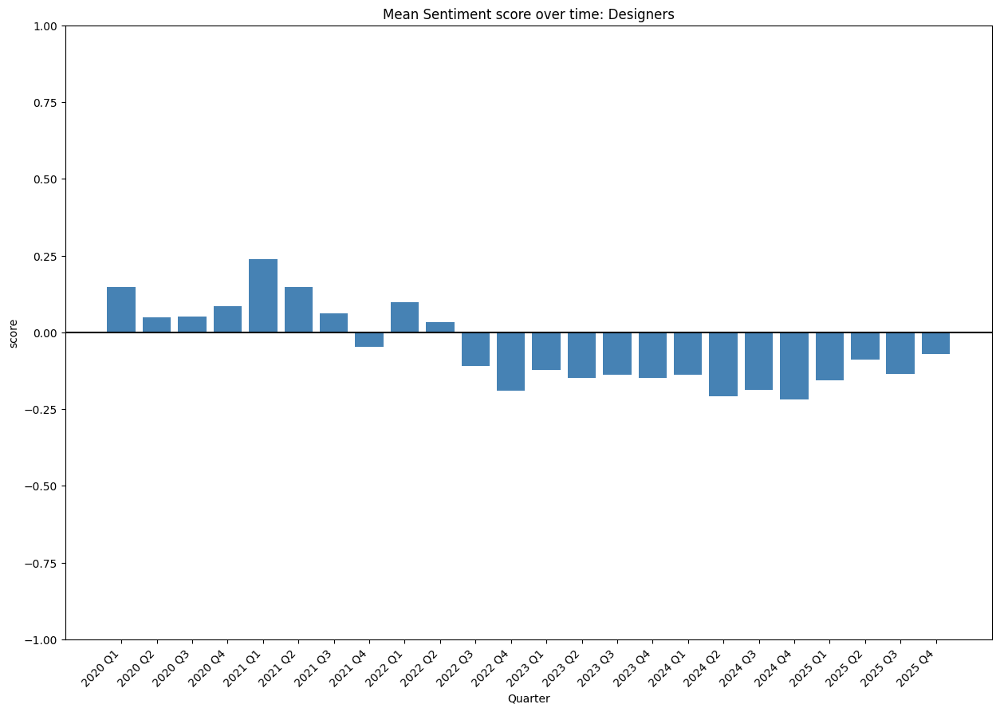

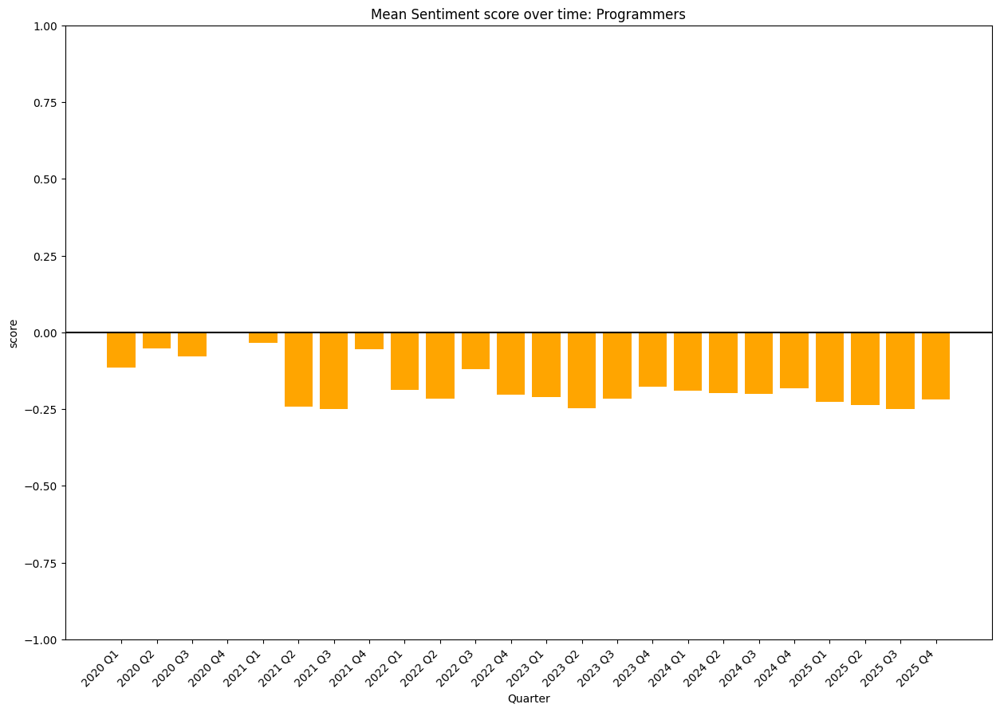

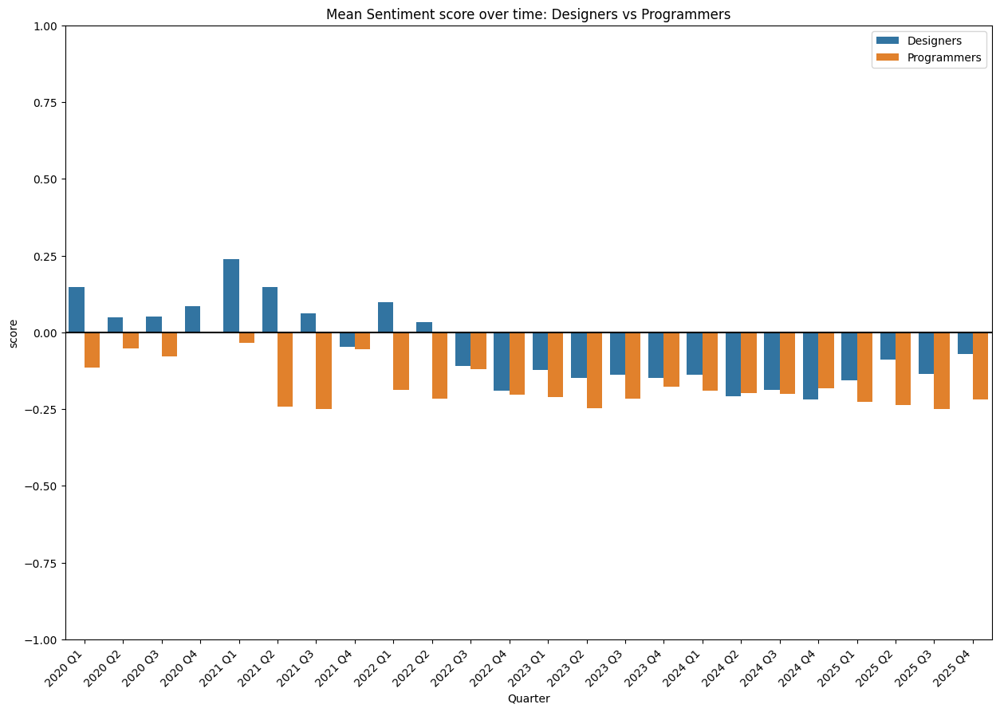

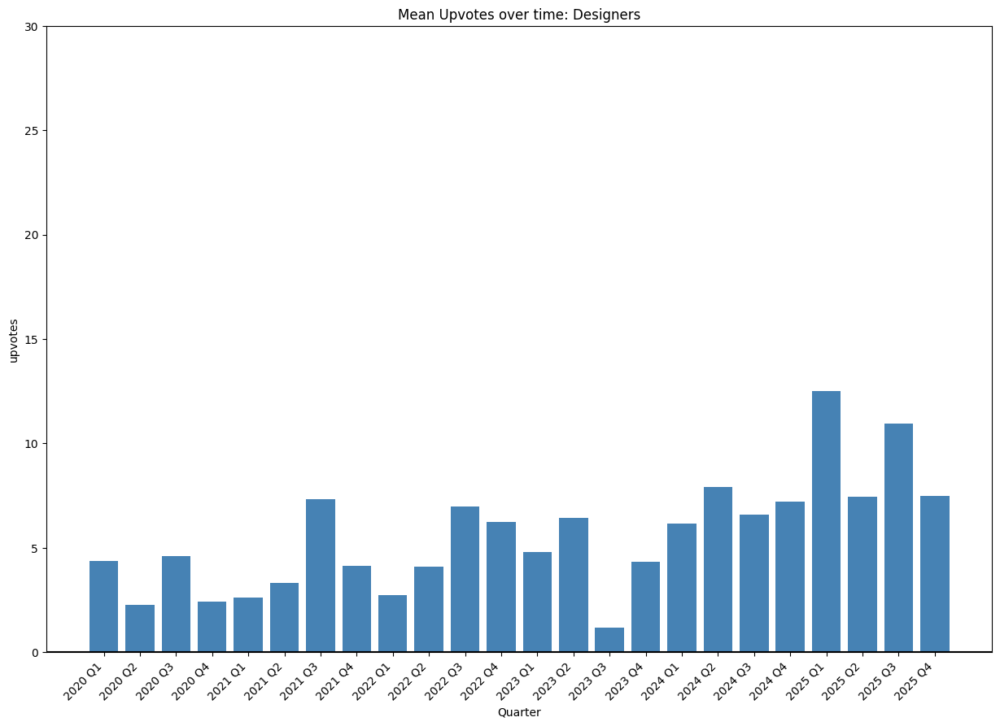

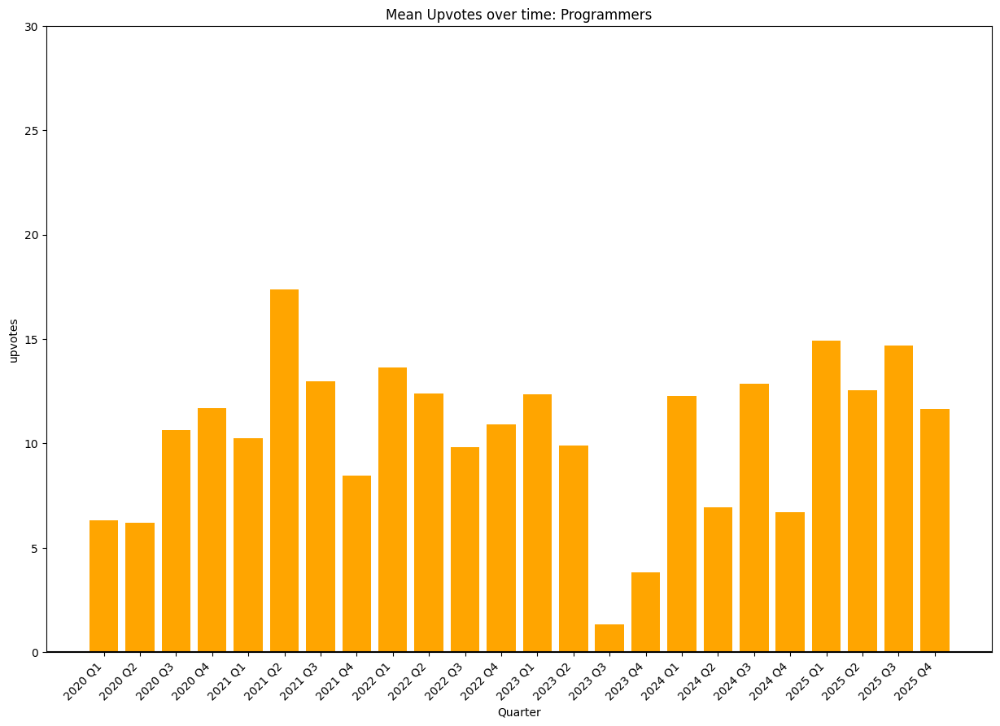

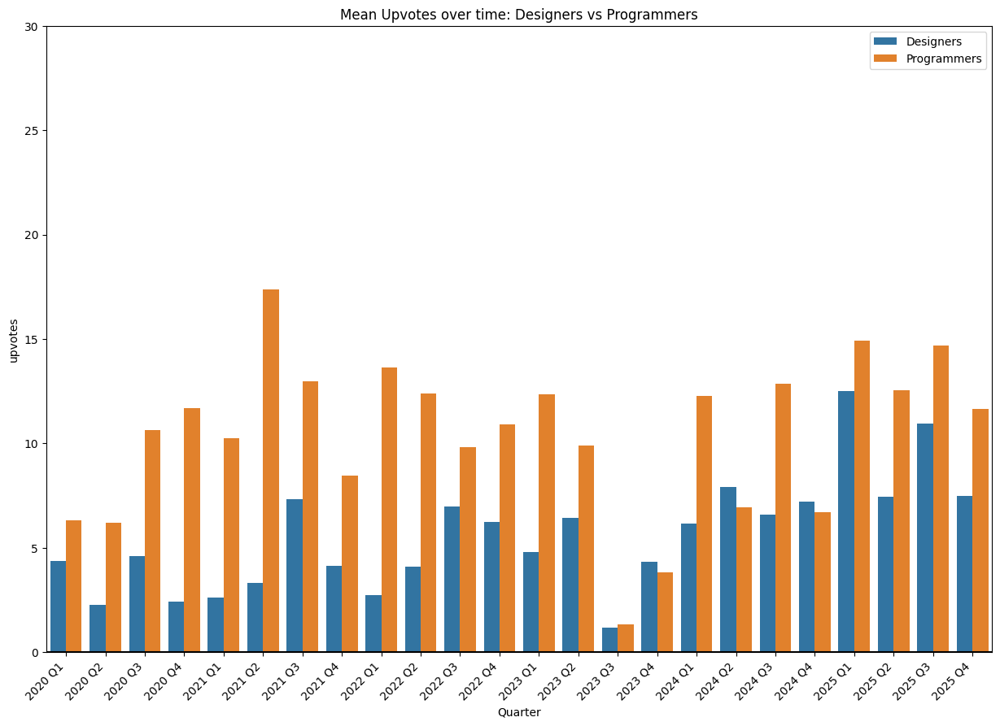

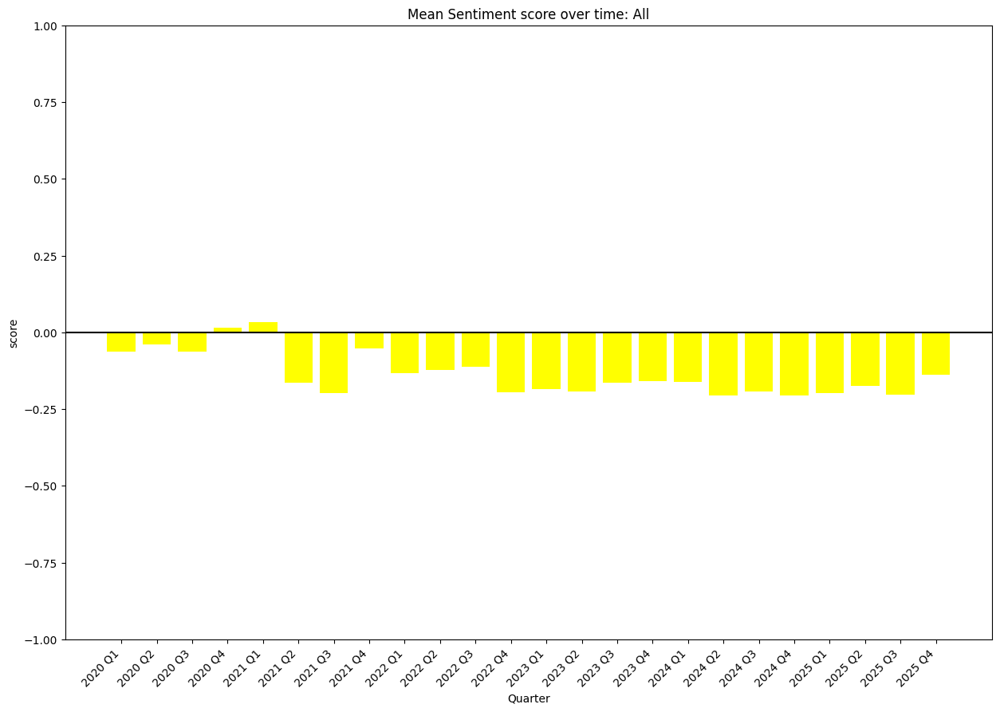

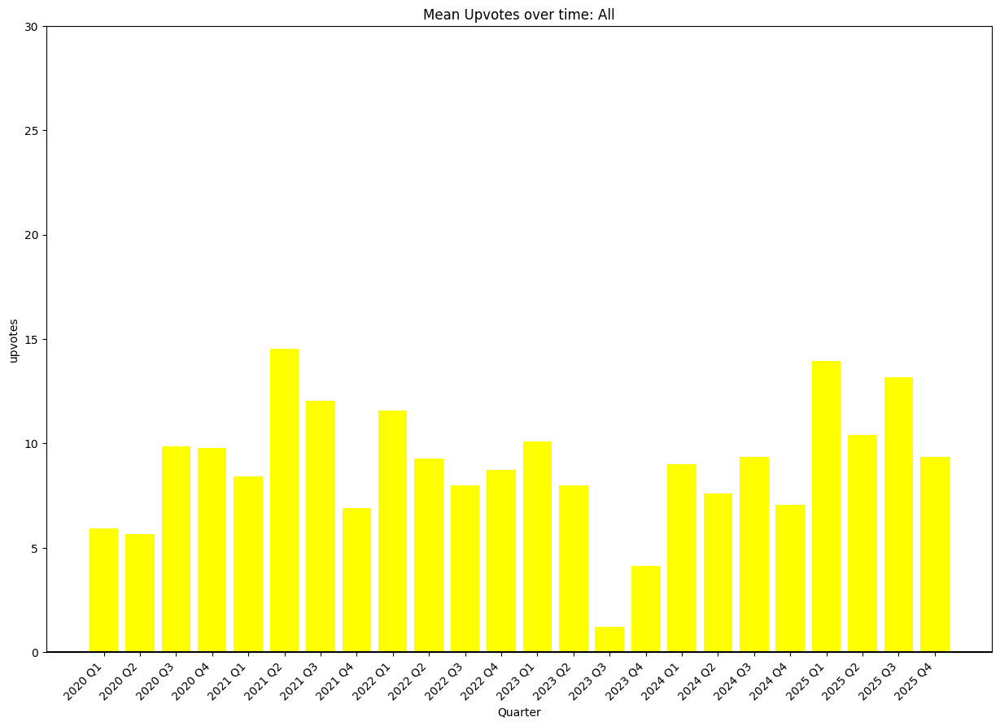

In [14]:
barplot_individual(quarter_designers, "Designers", "score", "steelblue")
barplot_individual(quarter_programmers, "Programmers", "score", "orange")
barplot_comparison(quarter_designers, "Designers", quarter_programmers, "Programmers", "score")

barplot_individual(quarter_designers, "Designers", "upvotes", "steelblue")
barplot_individual(quarter_programmers, "Programmers", "upvotes", "orange")
barplot_comparison(quarter_designers, "Designers", quarter_programmers, "Programmers", "upvotes")

barplot_individual(quarter_all, "All", "score", "yellow")
barplot_individual(quarter_all, "All", "upvotes", "yellow")

### Sentiment (barplot) with **quarterly data**


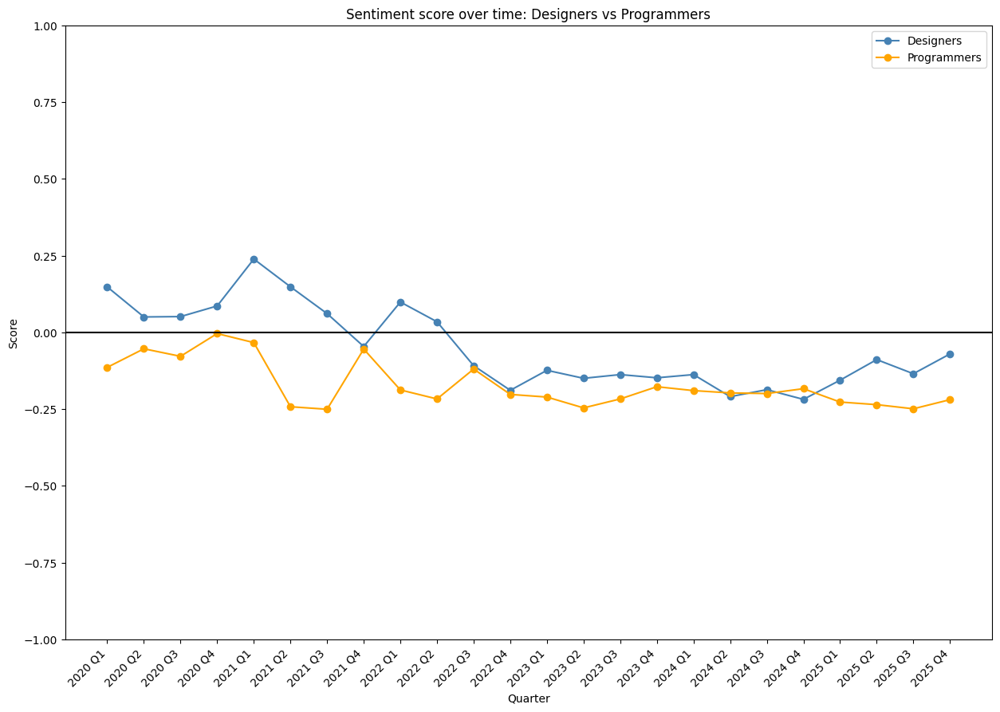

In [15]:
plt.figure(figsize = dimensions)
plt.plot(quarter_designers["quarter"], quarter_designers["score"], label = "Designers", color = "steelblue",  marker="o")
plt.plot(quarter_programmers["quarter"], quarter_programmers["score"], label = "Programmers", color = "orange",  marker="o")
plt.axhline(y = 0, color = "black")
plt.ylim(-1,1)
plt.xticks(rotation = 45, ha = "right")
plt.title("Sentiment score over time: Designers vs Programmers")
plt.legend()
plt.xlabel("Quarter")
plt.ylabel("Score")
plt.savefig("designers_vs_programmers(line)_sentiment_over_time(scaled).png")
plt.show()

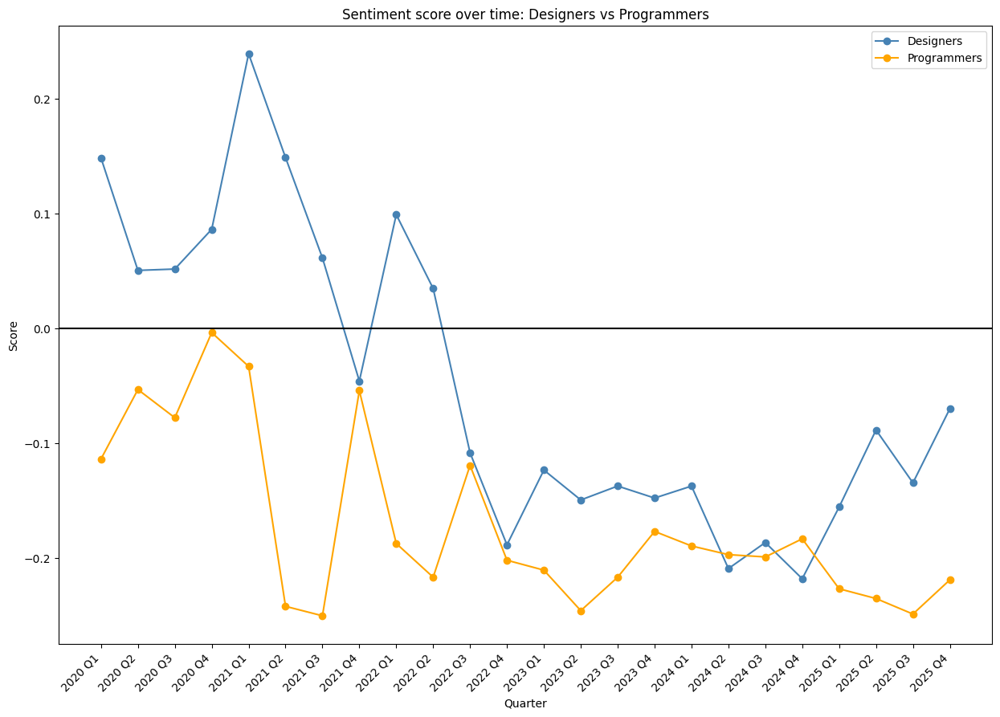

In [16]:
plt.figure(figsize = dimensions)
plt.plot(quarter_designers["quarter"], quarter_designers["score"], label = "Designers", color = "steelblue",  marker="o")
plt.plot(quarter_programmers["quarter"], quarter_programmers["score"], label = "Programmers", color = "orange",  marker="o")
plt.axhline(y = 0, color = "black")
plt.xticks(rotation = 45, ha = "right")
plt.title("Sentiment score over time: Designers vs Programmers")
plt.legend()
plt.xlabel("Quarter")
plt.ylabel("Score")
plt.savefig("designers_vs_programmers_sentiment(line)_over_time.png")
plt.show()

In [17]:
corr = quarter_designers["positive"].corr(quarter_designers["negative"])
print("Designers correlation:", corr)

corr = quarter_programmers["positive"].corr(quarter_programmers["negative"])
print("Programmers correlation:", corr)

Designers correlation: -0.902184789461378
Programmers correlation: -0.7127989826106258


### Number of comments over the time with **quarterly data**


In [18]:
def quarterly_size(df):
  df = df.copy()
  df["date"] = pd.to_datetime(df["date"])
  df["quarter"] = df["date"].dt.year.astype(str) + " Q" + df["date"].dt.quarter.astype(str)
  size = df.groupby("quarter").size().reset_index(name = "size")
  return size

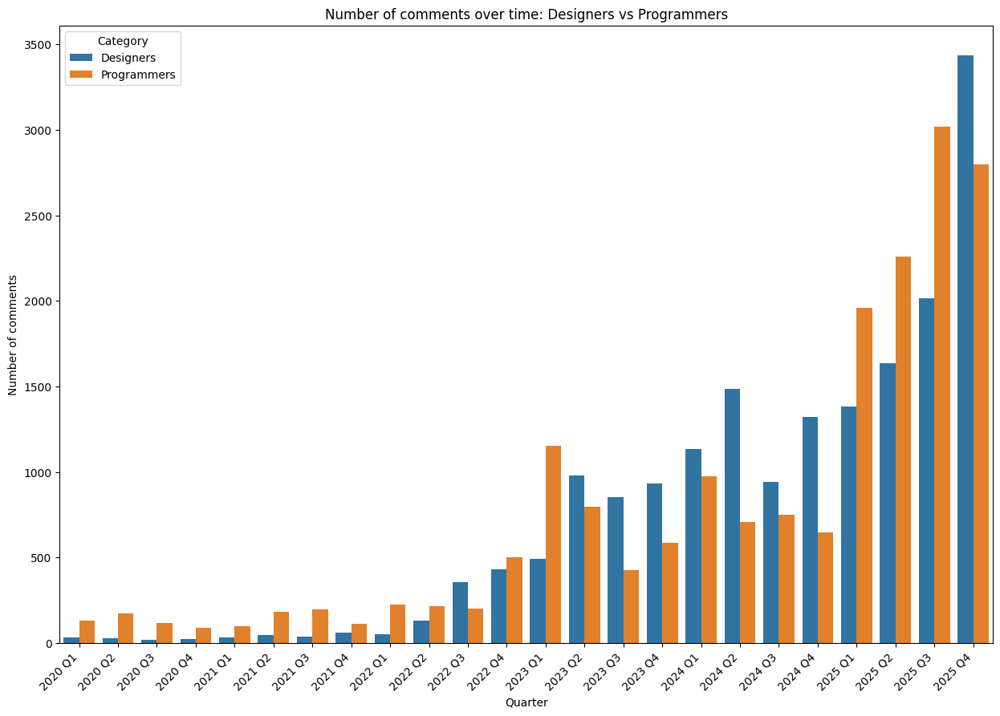

In [19]:
designers_size = quarterly_size(df_designers_sentiment)
programmers_size = quarterly_size(df_programmers_sentiment)
all_size = quarterly_size(df_all_sentiment)

designers_size ["category"] = "Designers"
programmers_size ["category"] = "Programmers"

comparison_df = pd.concat([designers_size, programmers_size], ignore_index = True)

plt.figure(figsize = dimensions)
sns.barplot(x = "quarter", y = "size", hue = "category", data = comparison_df)
plt.xticks(rotation = 45, ha = "right")
plt.title(f"Number of comments over time: Designers vs Programmers")
plt.xlabel("Quarter")
plt.ylabel("Number of comments")
plt.legend(title = "Category")
plt.savefig(f"designers_vs_programmers_number_of_comments_over_time.png")
plt.show()

### Weighted sentiment analysis for the whole time period on programmers and designers with **quarterly data**

**Weighted sentiment score:** we want to check how the sentiment score changes if more popular comments, so with high upvotes, influence the mean sentiment score.

In [20]:
def quarter_weighted_sentiment(df):
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
    df["quarter"] = df["date"].dt.year.astype(str) + " Q" + df["date"].dt.quarter.astype(str)
    df["log_upvotes"] = np.log1p(np.abs(df["upvotes"]))#fillna(0)))
    df["positive_weighted"] = df["positive"] * df["log_upvotes"]
    df["neutral_weighted"]  = df["neutral"]  * df["log_upvotes"]
    df["negative_weighted"] = df["negative"] * df["log_upvotes"]

    df["weighted_sum"] = df["positive_weighted"]*1 + df["neutral_weighted"]*0 + df["negative_weighted"]*(-1)

    quarter_weighted = df.groupby("quarter")[["positive_weighted","neutral_weighted","negative_weighted","weighted_sum","log_upvotes"]].sum().reset_index()
    quarter_weighted["score"] = quarter_weighted["weighted_sum"] / quarter_weighted["log_upvotes"]


    quarter_weighted["positive_weighted"] = quarter_weighted["positive_weighted"] / quarter_weighted["log_upvotes"]
    quarter_weighted["neutral_weighted"]  = quarter_weighted["neutral_weighted"]  / quarter_weighted["log_upvotes"]
    quarter_weighted["negative_weighted"] = quarter_weighted["negative_weighted"] / quarter_weighted["log_upvotes"]
    return quarter_weighted


In [21]:
quarter_weighted_designers = quarter_weighted_sentiment(df_designers_sentiment)
quarter_weighted_designers

,quarter,positive_weighted,neutral_weighted,negative_weighted,weighted_sum,log_upvotes,score
0,2020 Q1,0.361888,0.455734,0.182373,6.617019,36.860583,0.179515
1,2020 Q2,0.242636,0.522709,0.234652,0.251681,31.525310,0.007983
2,2020 Q3,0.331714,0.388298,0.279998,1.198450,23.173717,0.051716
3,2020 Q4,0.318575,0.448043,0.233401,2.024007,23.763105,0.085174
4,2021 Q1,0.439218,0.416901,0.143872,10.435164,35.331972,0.295346
5,2021 Q2,0.312838,0.493446,0.193711,6.906494,57.975940,0.119127
6,2021 Q3,0.299395,0.460419,0.240171,3.111093,52.531102,0.059224
7,2021 Q4,0.203909,0.555063,0.241014,-2.936127,79.131335,-0.037104
8,2022 Q1,0.283899,0.513516,0.202581,4.794085,58.955410,0.081317
9,2022 Q2,0.258216,0.483552,0.258232,-0.002735,170.327660,-0.000016


In [22]:
quarter_weighted_programmers = quarter_weighted_sentiment(df_programmers_sentiment)
quarter_weighted_programmers

,quarter,positive_weighted,neutral_weighted,negative_weighted,weighted_sum,log_upvotes,score
0,2020 Q1,0.192959,0.498394,0.308653,-21.454509,185.441841,-0.115694
1,2020 Q2,0.242279,0.472681,0.285049,-10.163849,237.640016,-0.042770
2,2020 Q3,0.222609,0.485703,0.291674,-12.709980,184.028150,-0.069065
3,2020 Q4,0.281957,0.465134,0.252909,4.129062,142.142767,0.029049
4,2021 Q1,0.230910,0.490904,0.278186,-6.846132,144.811662,-0.047276
5,2021 Q2,0.123876,0.511408,0.364715,-72.731719,301.993647,-0.240839
6,2021 Q3,0.115498,0.506003,0.378498,-82.383208,313.243574,-0.263000
7,2021 Q4,0.224461,0.491199,0.284348,-9.968247,166.451430,-0.059887
8,2022 Q1,0.131897,0.520354,0.347754,-75.956911,351.885176,-0.215857
9,2022 Q2,0.116935,0.520350,0.362720,-81.103759,329.978009,-0.245785


In [23]:
quarter_weighted_all = quarter_weighted_sentiment(df_all_sentiment)
quarter_weighted_all

,quarter,positive_weighted,neutral_weighted,negative_weighted,weighted_sum,log_upvotes,score
0,2020 Q1,0.220969,0.491320,0.287714,-14.837490,222.302424,-0.066745
1,2020 Q2,0.242321,0.478540,0.279146,-9.912168,269.165326,-0.036826
2,2020 Q3,0.234811,0.474809,0.290368,-11.511530,207.201867,-0.055557
3,2020 Q4,0.287202,0.462686,0.250115,6.153069,165.905873,0.037088
4,2021 Q1,0.271766,0.476390,0.251842,3.589032,180.143634,0.019923
5,2021 Q2,0.154310,0.508515,0.337173,-65.825225,359.969587,-0.182863
6,2021 Q3,0.141908,0.499457,0.358632,-79.272116,365.774676,-0.216724
7,2021 Q4,0.217839,0.511777,0.270385,-12.904374,245.582764,-0.052546
8,2022 Q1,0.153709,0.519373,0.326922,-71.162826,410.840586,-0.173213
9,2022 Q2,0.165033,0.507822,0.327147,-81.106494,500.305669,-0.162114


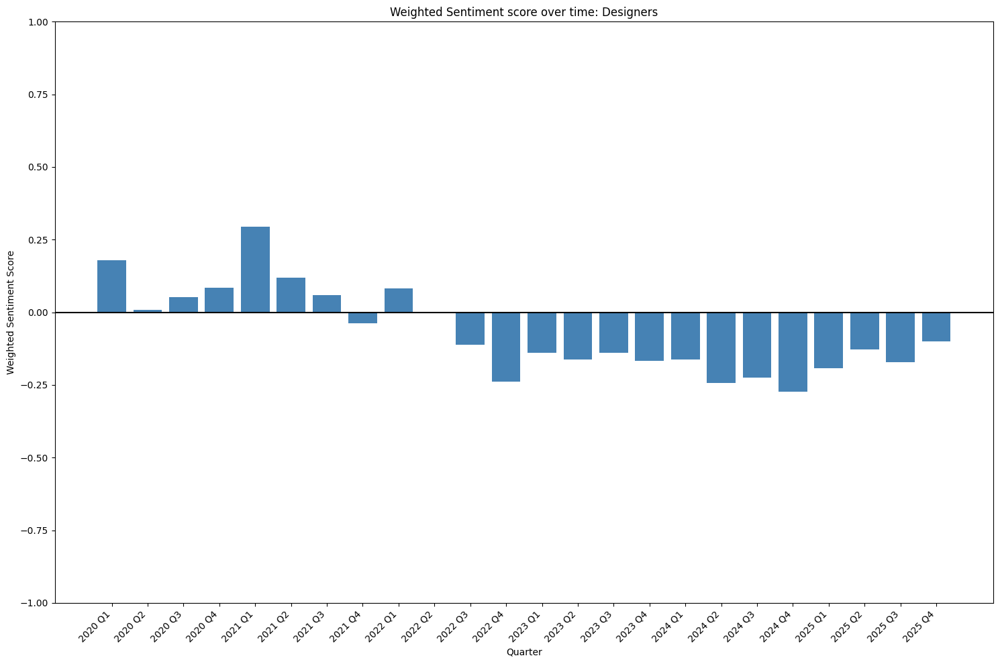

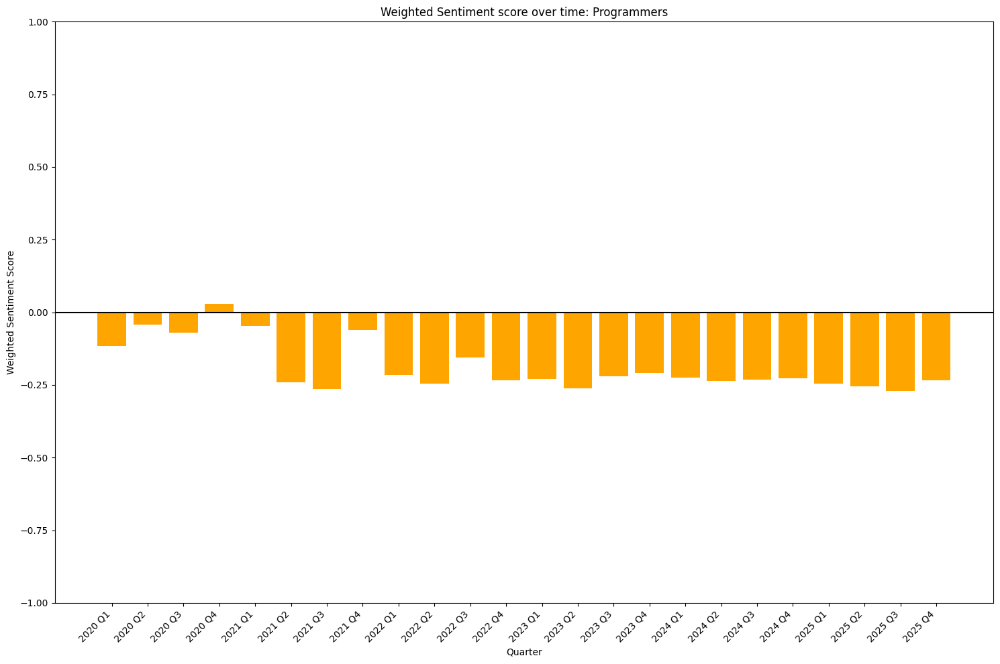

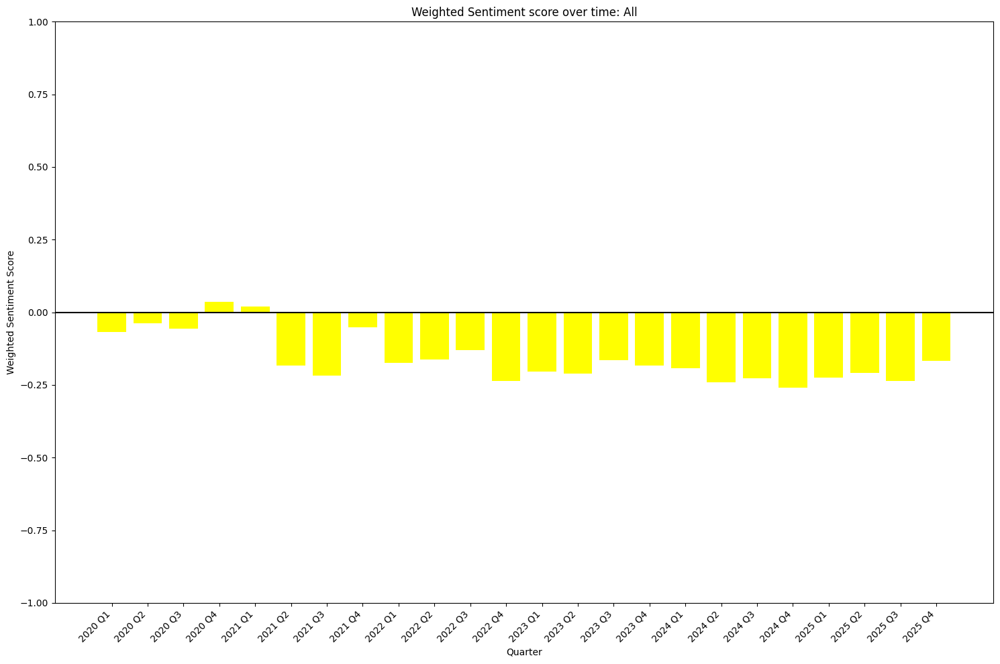

In [24]:
def weighted_sentiment_plot(df, category, color):
    plt.figure(figsize = dimensions)
    plt.bar(df["quarter"], df["score"], color = color)
    plt.ylim(-1,1)
    plt.xticks(rotation = 45, ha = "right")
    plt.axhline(y = 0, color = "black")
    plt.title(f"Weighted Sentiment score over time: {category}")
    plt.xlabel("Quarter")
    plt.ylabel("Weighted Sentiment Score")
    plt.tight_layout()
    plt.savefig(f"{category}_weighted_sentiment_over_time.png")
    plt.show()
    plt.close()

weighted_sentiment_plot(quarter_weighted_designers, "Designers", color = "steelblue")
weighted_sentiment_plot(quarter_weighted_programmers, "Programmers", color = "orange")
weighted_sentiment_plot(quarter_weighted_all, "All", color = "yellow")

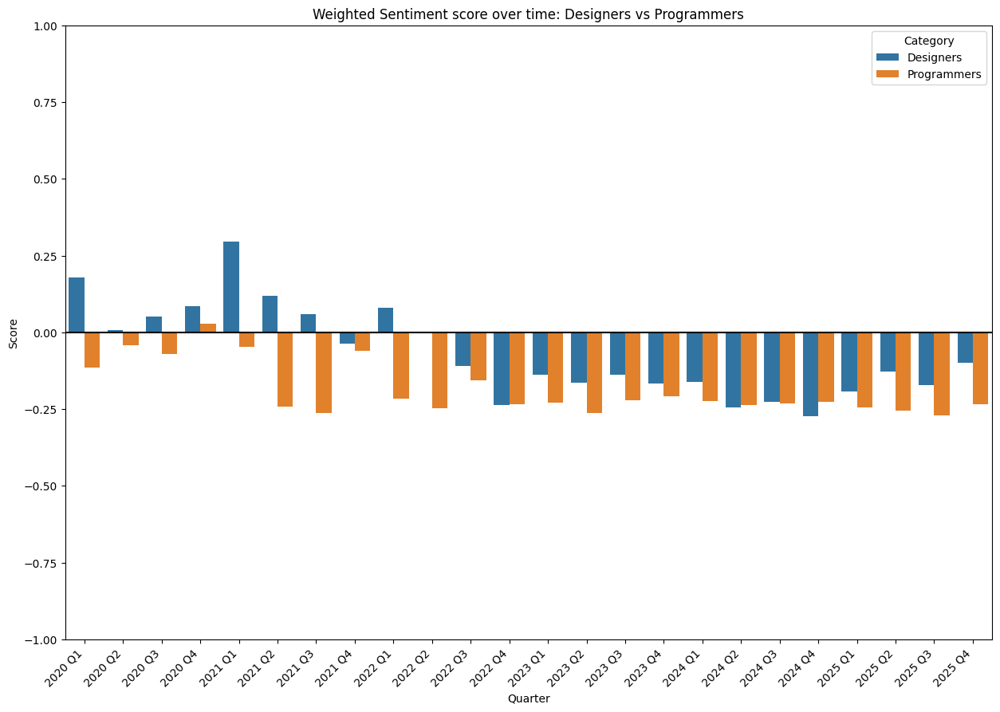

In [25]:
quarter_weighted_designers["category"] = "Designers"
quarter_weighted_programmers["category"] = "Programmers"
comparison_df = pd.concat([quarter_weighted_designers, quarter_weighted_programmers], ignore_index = True)
plt.figure(figsize = dimensions)
sns.barplot(x = "quarter", y = "score", hue = "category", data = comparison_df)
plt.ylim(-1,1)
plt.xticks(rotation = 45, ha = "right")
plt.axhline(y = 0, color = "black")
plt.xlabel("Quarter")
plt.ylabel("Score")
plt.title(f"Weighted Sentiment score over time: Designers vs Programmers")
plt.legend(title = "Category")
plt.savefig(f"designers_vs_programmers_weighted_sentiment_over_time.png")
plt.show()

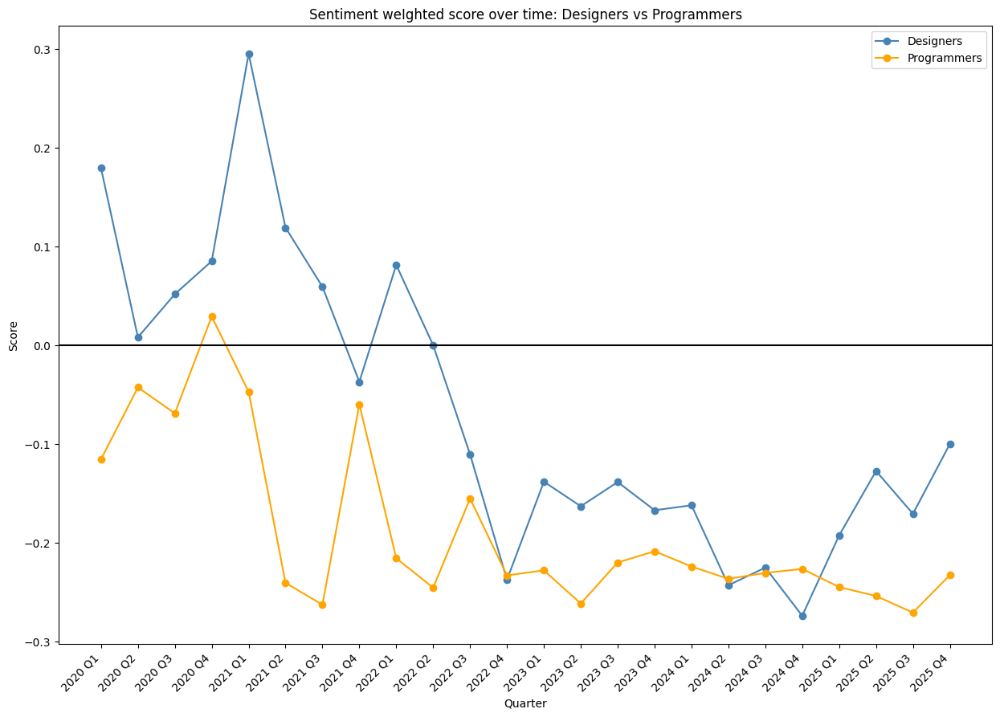

In [26]:
plt.figure(figsize = dimensions)
plt.plot(quarter_weighted_designers["quarter"], quarter_weighted_designers["score"], label = "Designers", color = "steelblue", marker = "o")
plt.plot(quarter_weighted_programmers["quarter"], quarter_weighted_programmers["score"], label = "Programmers", color = "orange", marker = "o")
plt.axhline(y = 0, color = "black")
plt.xticks(rotation = 45, ha = "right")
plt.title("Sentiment weIghted score over time: Designers vs Programmers")
plt.legend()
plt.xlabel("Quarter")
plt.ylabel("Score")
plt.savefig("designers_vs_programmers_sentiment (line)_weighted_over_time.png")
plt.show()

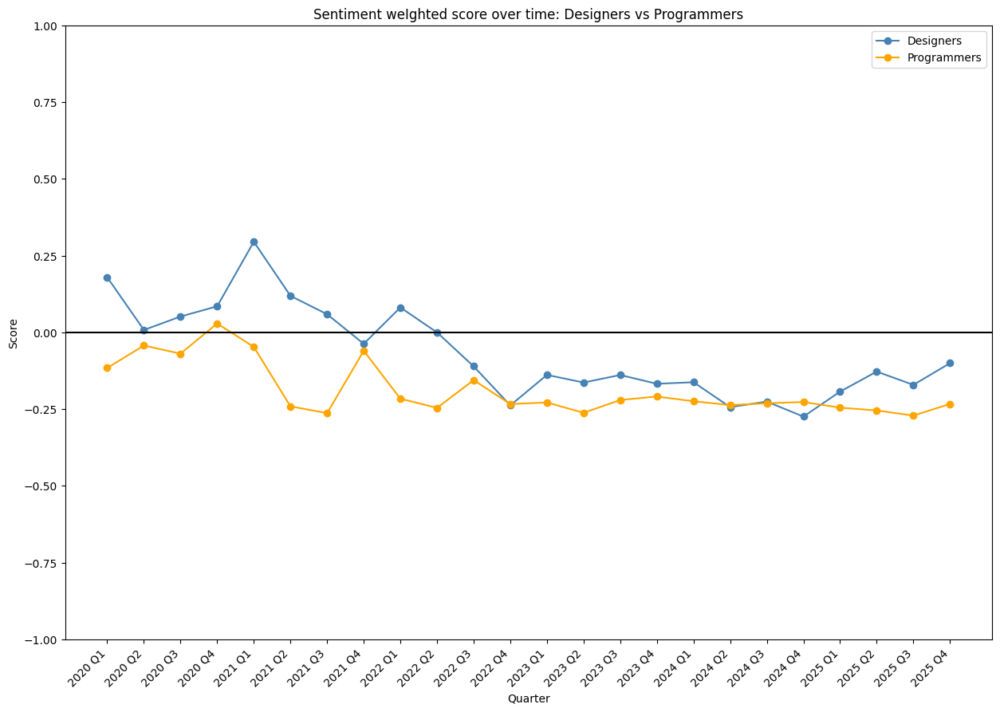

In [27]:
plt.figure(figsize = dimensions)
plt.plot(quarter_weighted_designers["quarter"], quarter_weighted_designers["score"], label = "Designers", color = "steelblue", marker = "o")
plt.plot(quarter_weighted_programmers["quarter"], quarter_weighted_programmers["score"], label = "Programmers", color = "orange", marker = "o")
plt.axhline(y = 0, color = "black")
plt.ylim(-1,1)
plt.xticks(rotation = 45, ha = "right")
plt.title("Sentiment weIghted score over time: Designers vs Programmers")
plt.legend()
plt.xlabel("Quarter")
plt.ylabel("Score")
plt.savefig("designers_vs_programmers_sentiment(line)_weighted_over_time(scaled).png")
plt.show()

###Barplot with three bars: negative, neutral, positive **for each YEAR**

In [28]:
def yearly_sentiment(df):
  df = df.copy()
  df["date"] = pd.to_datetime(df["date"])
  df["year"] = df["date"].dt.year
  yearly = df.groupby("year")[["positive", "neutral", "negative"]].mean().reset_index()
  yearly["score"] = (yearly["positive"] * 1 + yearly["neutral"] * 0 + yearly["negative"] * (-1))
  return yearly

yearly_designers = yearly_sentiment(df_designers_sentiment)
yearly_programmers = yearly_sentiment(df_programmers_sentiment)
yearly_all = yearly_sentiment(df_all_sentiment)
yearly_all


,year,positive,neutral,negative,score
0,2020,0.235370,0.489236,0.275395,-0.040026
1,2021,0.190207,0.503482,0.306309,-0.116102
2,2022,0.171260,0.503982,0.324759,-0.153498
3,2023,0.183124,0.457369,0.359508,-0.176384
4,2024,0.182632,0.443520,0.373848,-0.191217
5,2025,0.182590,0.461262,0.356149,-0.173559


In [29]:
def barplot_yearly_sentiment(df, category):
  plt.figure(figsize = dimensions)
  df_plot = df.copy()
  x = np.arange(len(df["year"]))
  width = 0.25
  plt.bar(x - width, df["positive"], width = width, label = "Positive", color = "green")
  plt.bar(x, df["neutral"], width = width, label = "Neutral", color = "grey")
  plt.bar(x + width, df["negative"], width = width, label = "Negative", color = "red")
  plt.xticks(x, df["year"], rotation = 45, ha = "right")
  plt.title(f"Yearly Sentiment score: {category}")
  plt.xlabel("Year")
  plt.ylabel("Score")
  plt.ylim(0,1)
  plt.legend(["Positive", "Neutral", "Negative"])
  plt.axhline(y = 0, color = "black")
  plt.savefig(f"{category}_yearly_sentiment.png")
  plt.show()
  plt.close()

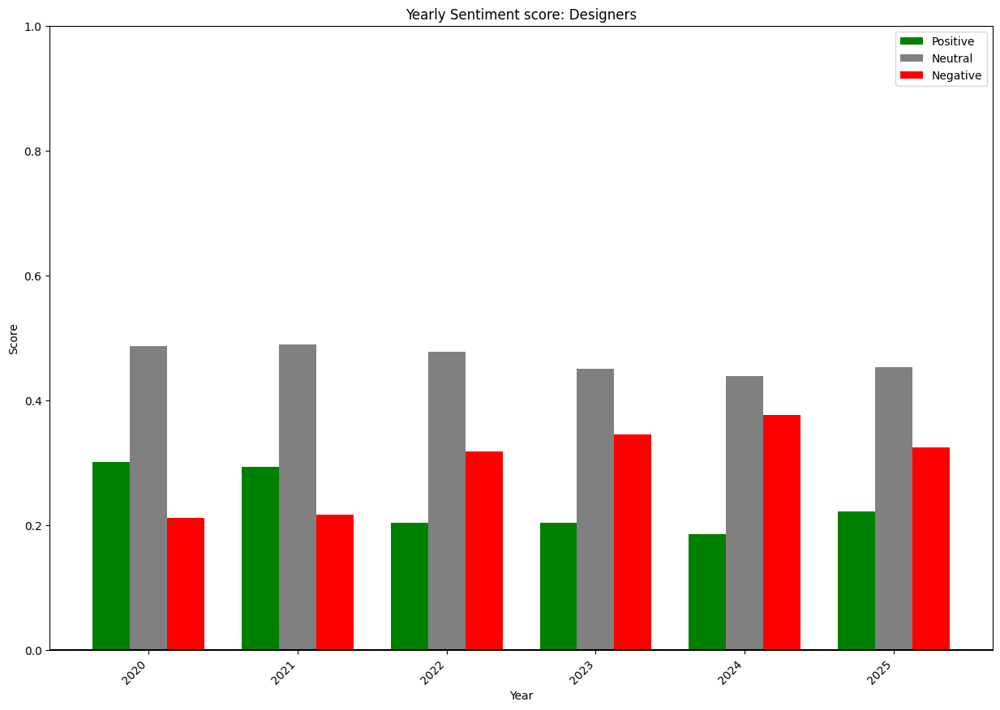

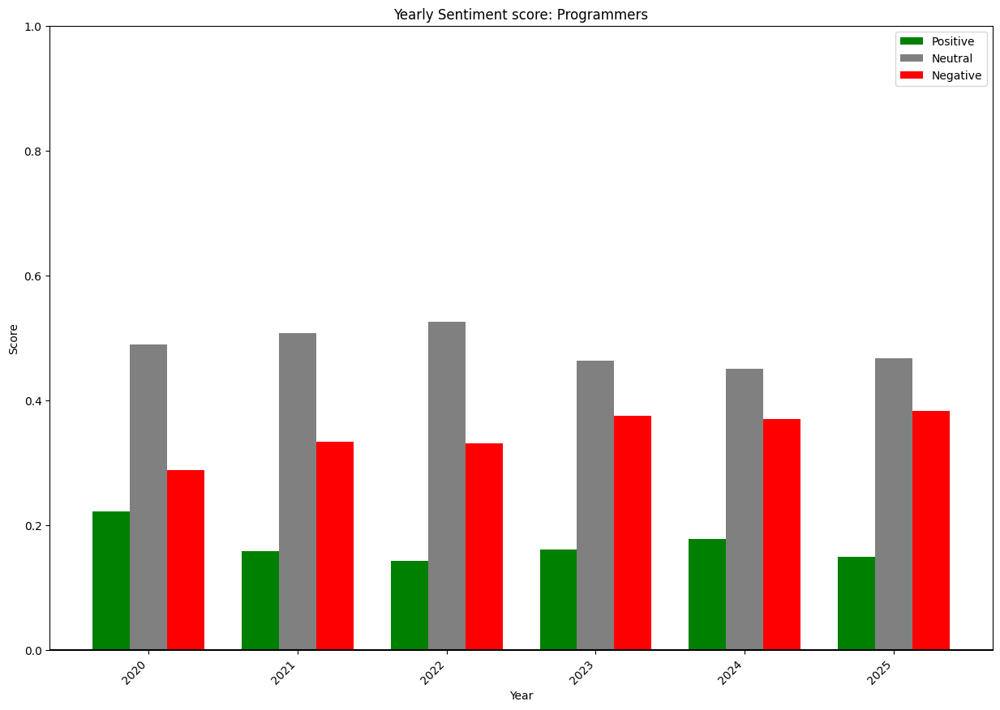

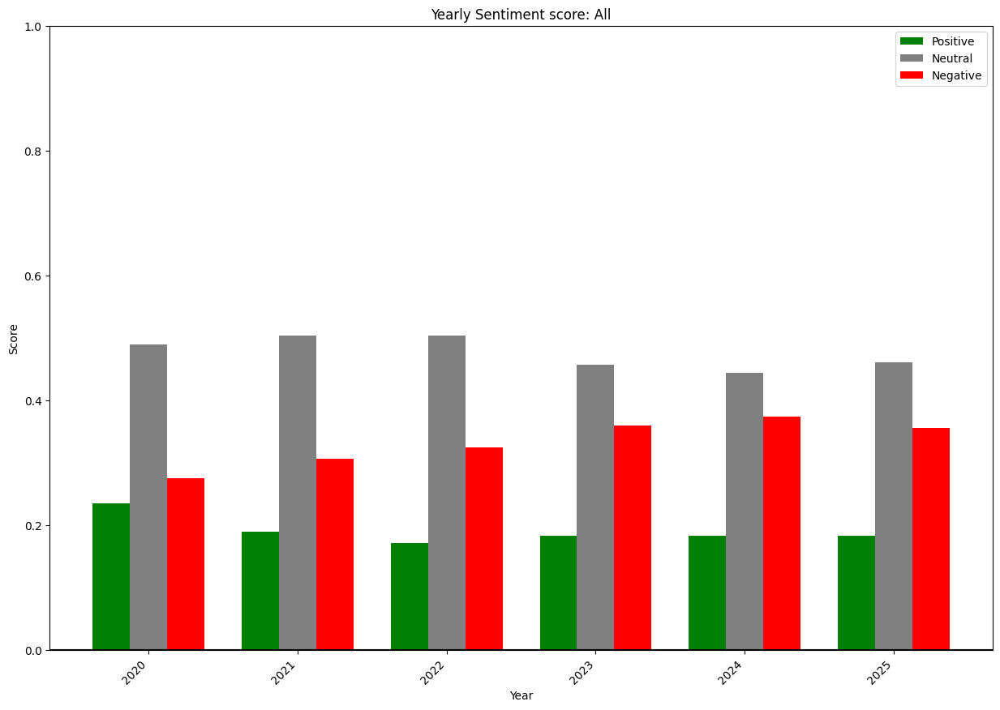

In [30]:
barplot_yearly_sentiment(yearly_designers, "Designers")
barplot_yearly_sentiment(yearly_programmers, "Programmers")
barplot_yearly_sentiment(yearly_all, "All")

###Regression




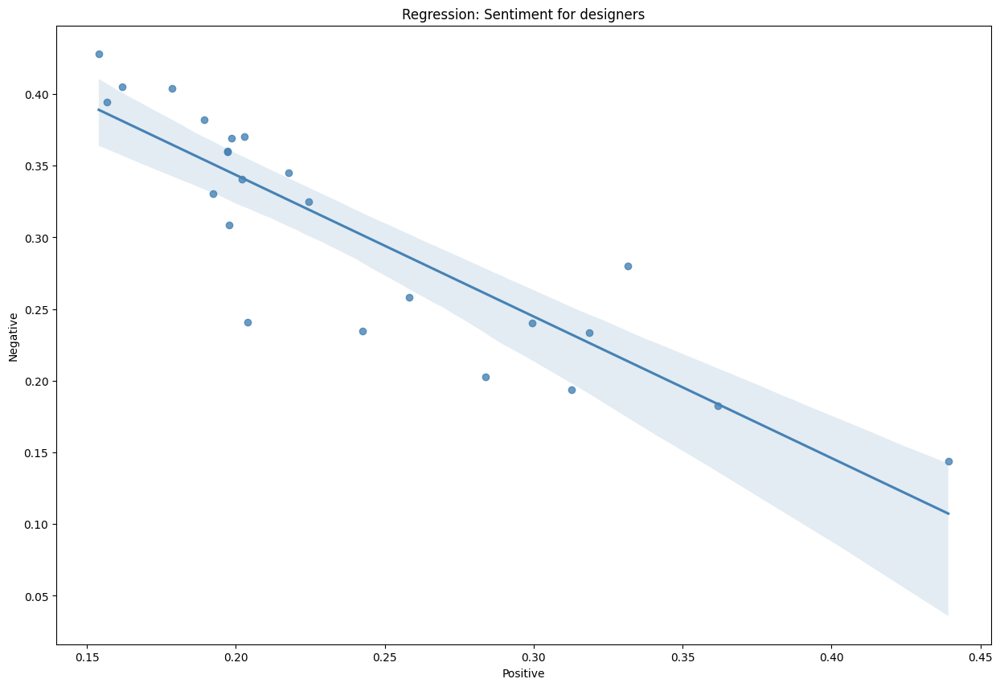

In [55]:
plt.figure(figsize = dimensions)
sns.regplot(
    x = "positive_weighted",
    y = "negative_weighted",
    data = quarter_weighted_designers,
    marker = "o",
    color = "steelblue")

plt.xlabel("Positive")
plt.ylabel("Negative")
plt.title("Regression: Sentiment for designers")
plt.savefig("designers_regression.png")
plt.show()

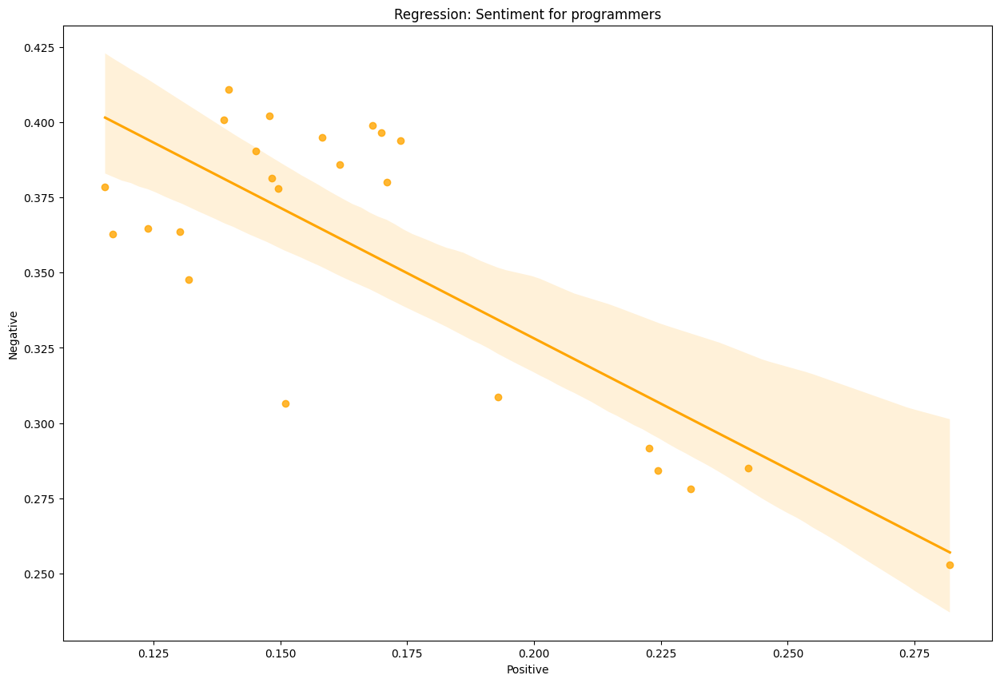

In [32]:
plt.figure(figsize = dimensions)
sns.regplot(
    x = "positive_weighted",
    y = "negative_weighted",
    data = quarter_weighted_programmers,
    marker = "o",
    color = "orange")

plt.xlabel("Positive")
plt.ylabel("Negative")
plt.title("Regression: Sentiment for programmers")
plt.savefig("programmers_regression.png")
plt.show()


# Topics sentiment

In [49]:
def plot_sentiment_dual(topic_sentiment, topic_name, category, method, weighted, color, qty, all_quarters):
    topic_sentiment = topic_sentiment.set_index('quarter').reindex(all_quarters).fillna(0).reset_index()
    if weighted:
      label = "Weighted "
    else:
      label = ""

    #Line plot
    plt.figure(figsize = (8,4))
    plt.plot(topic_sentiment["quarter"], topic_sentiment["score"], marker = "o", color = color)
    plt.axhline(0, color = "black", alpha = 0.6)
    plt.xlabel("Quarter")
    plt.ylabel("Score")
    plt.title(f"{label}Sentiment: {category}, {topic_name} (QTY = {qty})")
    plt.ylim(-1,1)
    plt.xticks(rotation = 45, ha = "right")
    plt.savefig(f"{category}_{method}_{label}_{topic_name}_line.png")
    plt.show()
    plt.close()

    #Bar plot
    plt.figure(figsize = (8,4))
    plt.bar(topic_sentiment["quarter"], topic_sentiment["score"], color = color)
    plt.axhline(0, color = "black", alpha = 0.6)
    plt.xlabel("Quarter")
    plt.ylabel("Score")
    plt.title(f"{label} Sentiment: {category}, {topic_name} (QTY = {qty})")
    plt.ylim(-1,1)
    plt.xticks(rotation = 45, ha = "right")
    plt.savefig(f"{category}_{method}_{label}_{topic_name}_bar.png")
    plt.show()
    plt.close()


In [40]:
df_designers_sentiment["date"] = pd.to_datetime(df_designers_sentiment["date"])
df_programmers_sentiment["date"] = pd.to_datetime(df_programmers_sentiment["date"])

In [50]:
def run_plots(topics_df, df_sentiment, category, method, color):
  all_quarters = (df_sentiment["date"].dt.year.astype(str) +" Q"+ df_sentiment["date"].dt.quarter.astype(str))
  all_quarters = sorted(all_quarters.unique())
  n_topics = topics_df.shape[1] - 1

  for t in range(n_topics):
    idx = topics_df[topics_df[f"cluster_{t}"] == 1].index
    topic_comments = df_sentiment.loc[idx]
    qty = topic_comments.shape[0]

    sentiment_unweighted = sentiment_quarter(topic_comments)
    plot_sentiment_dual(
      topic_sentiment = sentiment_unweighted,
      topic_name = f"Topic {t}",
      category = category,
      method = method,
      weighted = False,
      color = color,
      qty = qty,
      all_quarters = all_quarters)

    sentiment_weighted = quarter_weighted_sentiment(topic_comments)
    plot_sentiment_dual(
      topic_sentiment = sentiment_weighted,
      topic_name = f"Topic {t}",
      category = category,
      method = method,
      weighted = True,
      color = color,
      qty = qty,
      all_quarters = all_quarters)

In [36]:
designers_topics_bert = pd.read_csv("C_designers_B.csv")
programmers_topics_bert = pd.read_csv("C_programmers_B.csv")

print(f"Designers topics: {designers_topics_bert.shape[1]}")
print(f"Programmers topics: {programmers_topics_bert.shape[1]}")

Designers topics: 8
Programmers topics: 65


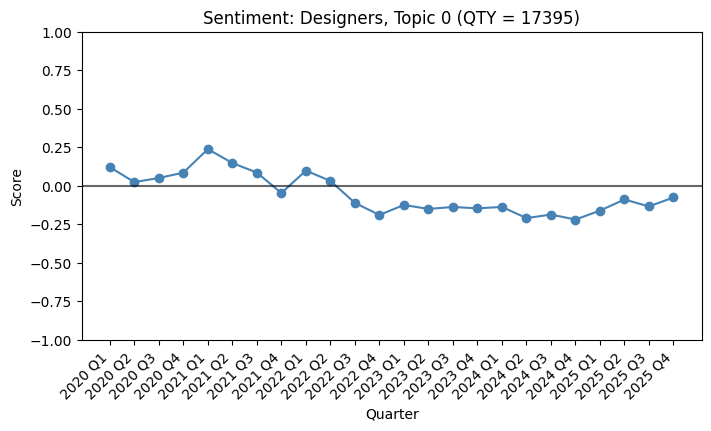

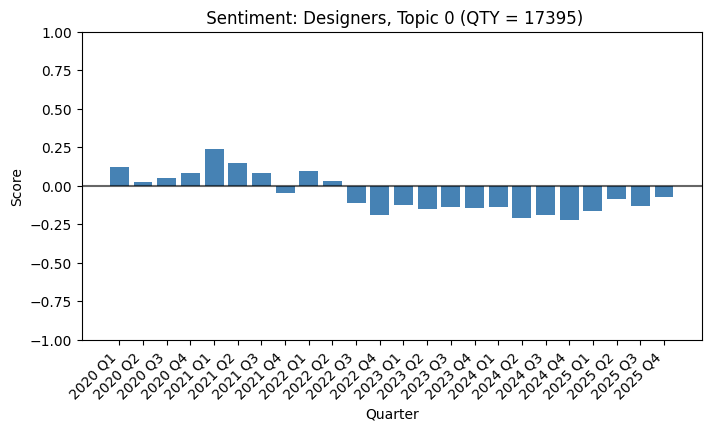

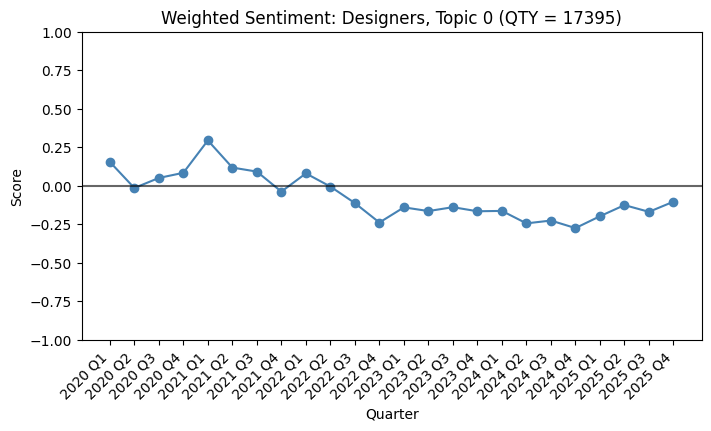

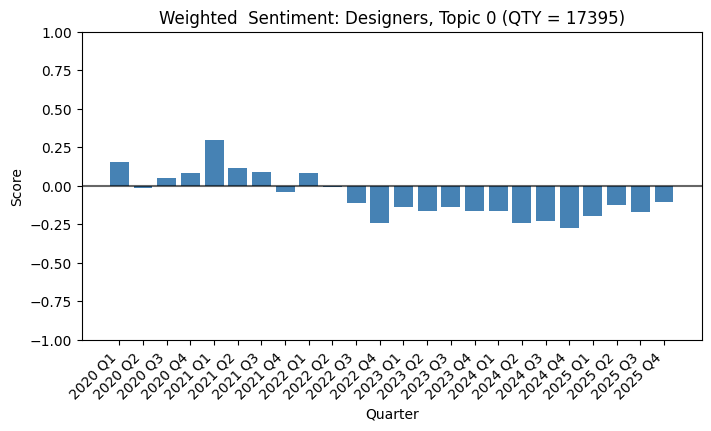

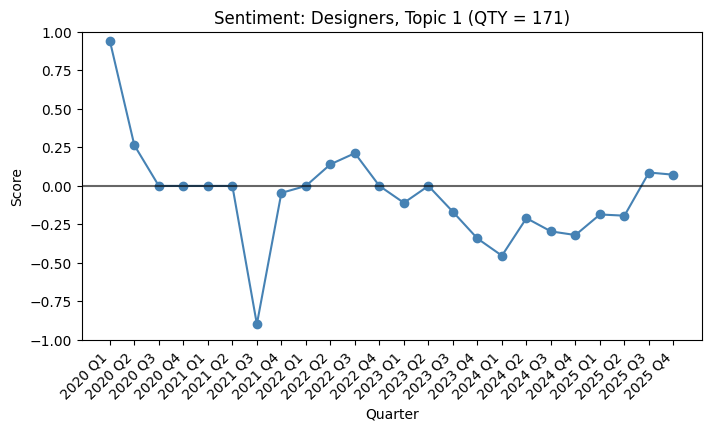

...

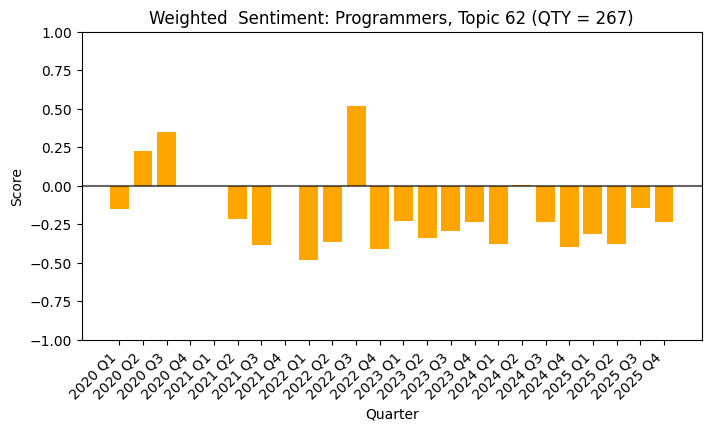

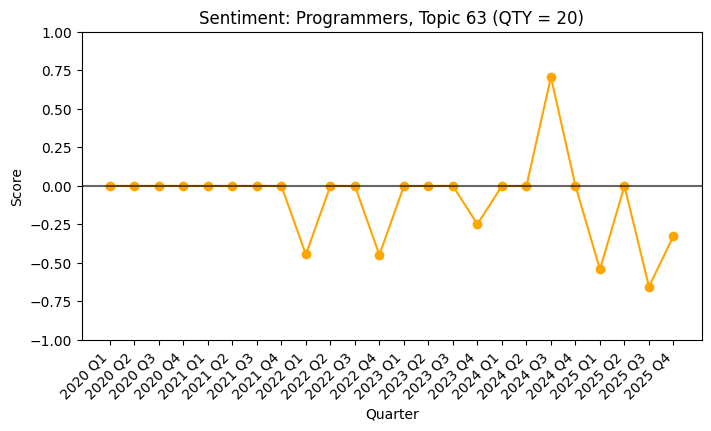

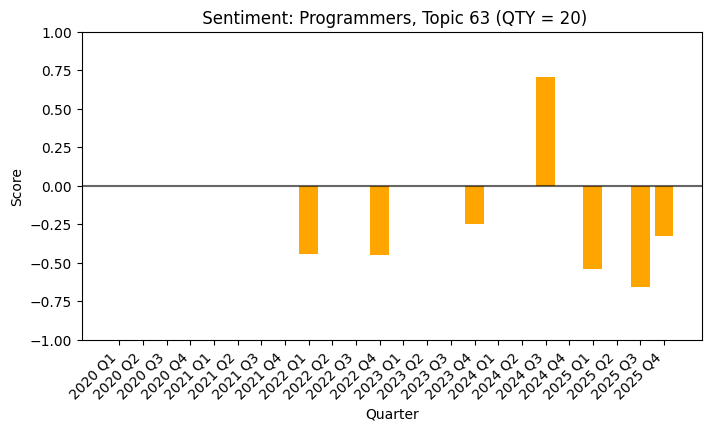

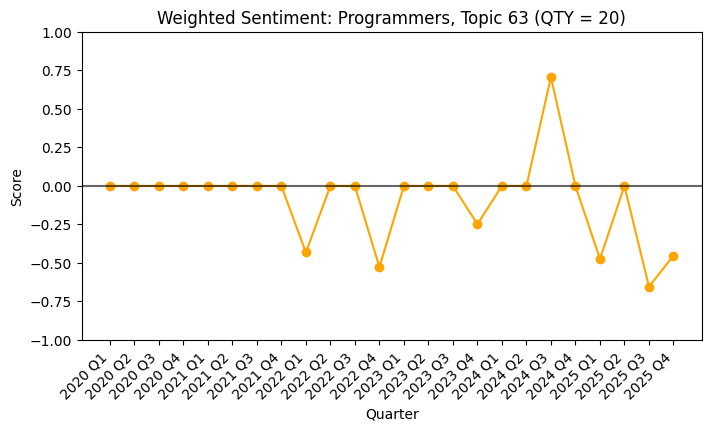

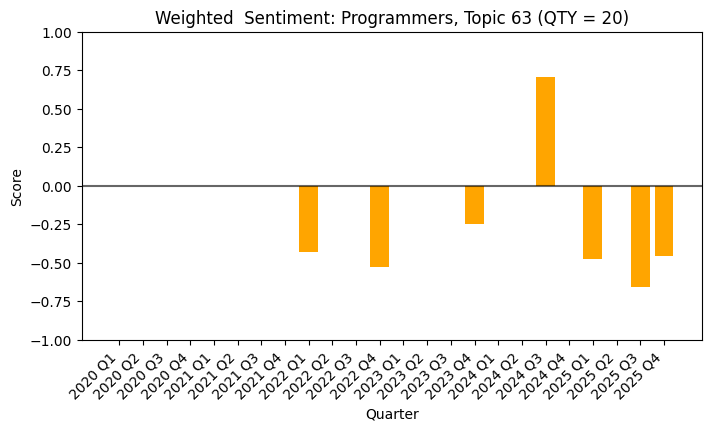

In [51]:
run_plots(topics_df=designers_topics_bert, df_sentiment=df_designers_sentiment, category="Designers", method="bert", color="steelblue")
run_plots(topics_df=programmers_topics_bert, df_sentiment=df_programmers_sentiment, category="Programmers", method="bert", color="orange")

In [53]:
designers_topics_louvain = pd.read_csv("C_Designers_L.csv")
programmers_topics_louvain = pd.read_csv("C_Programmers_L.csv")

print(f"Designers topics: {designers_topics_louvain.shape[1]}")
print(f"Programmers topics: {programmers_topics_louvain.shape[1]}")

Designers topics: 9
Programmers topics: 6


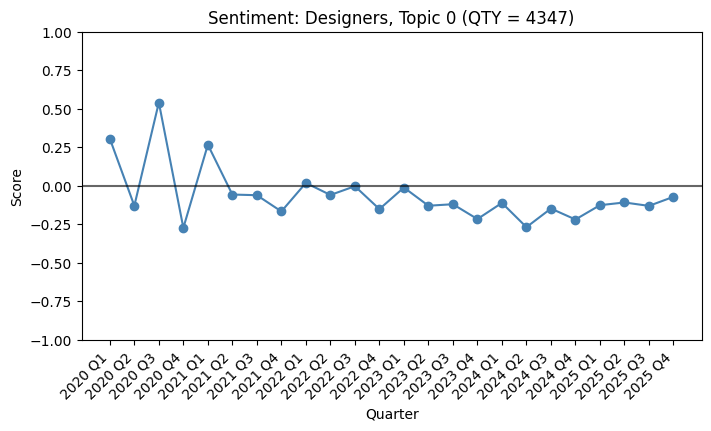

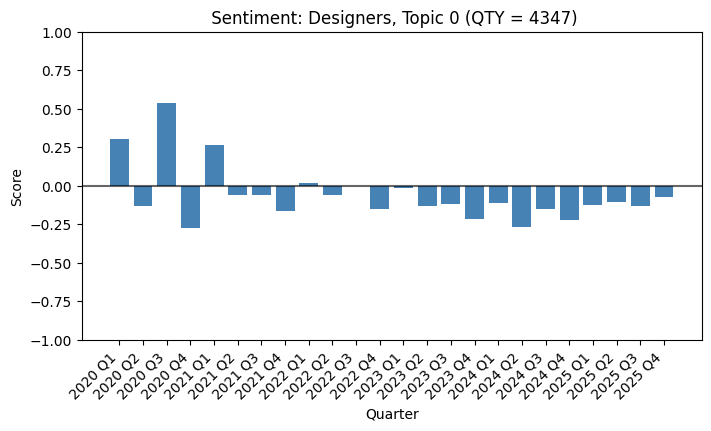

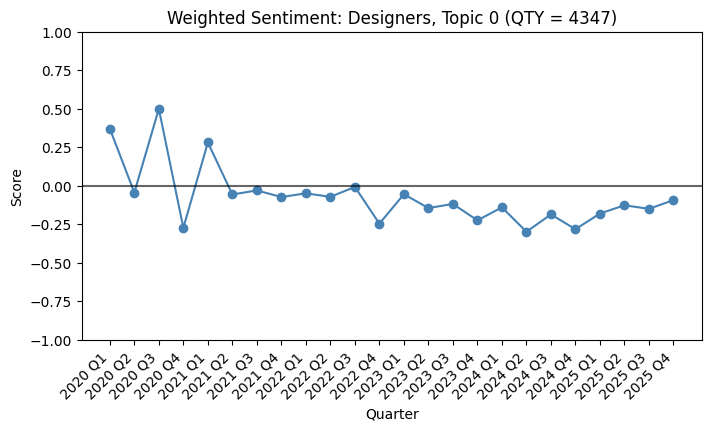

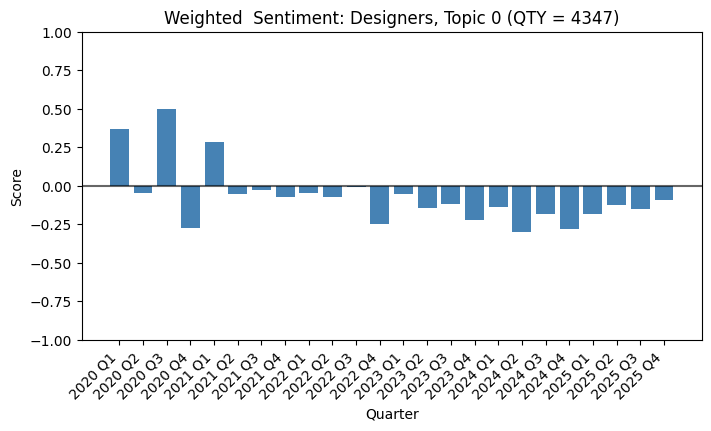

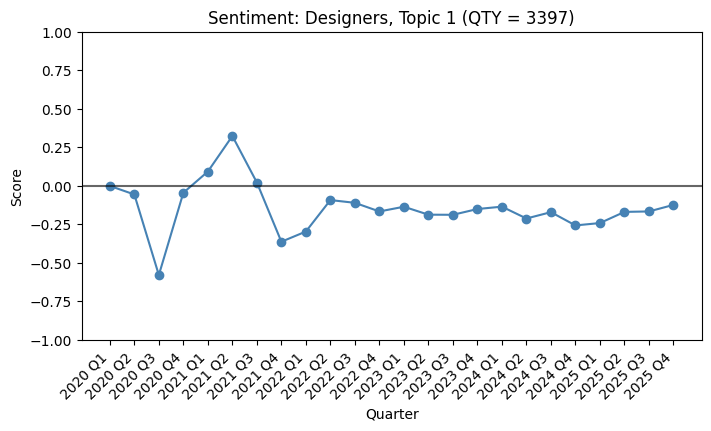

...

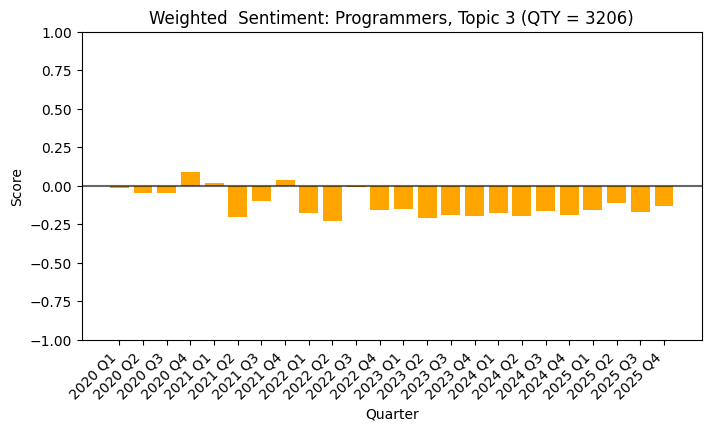

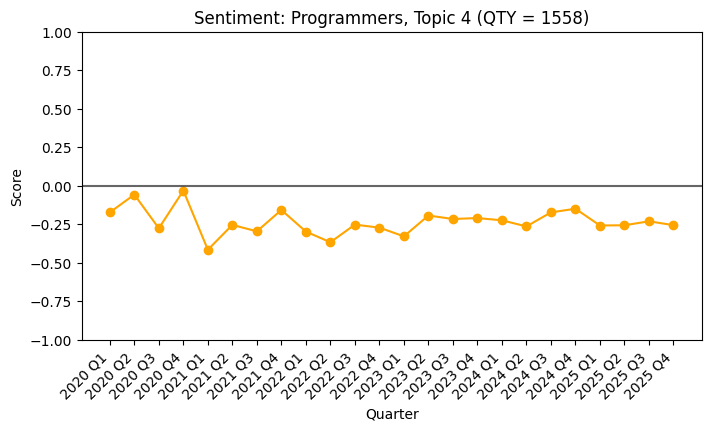

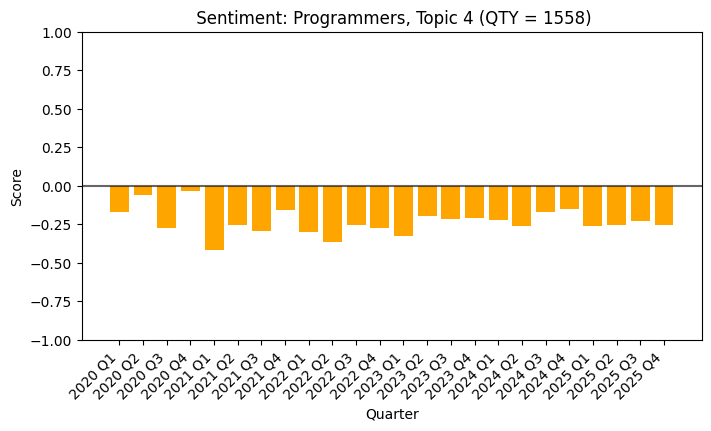

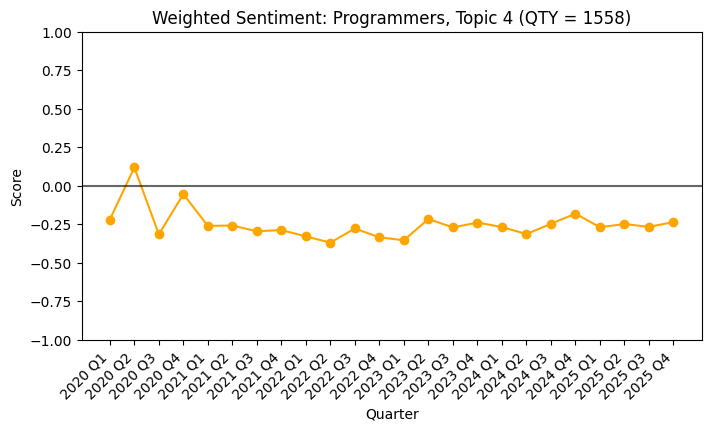

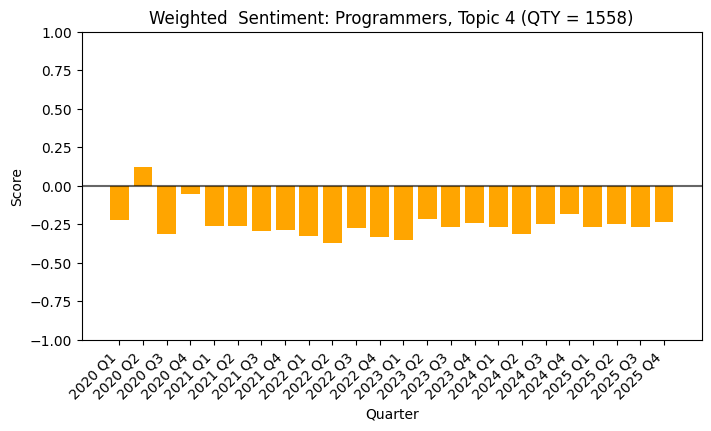

In [54]:
run_plots(topics_df=designers_topics_louvain, df_sentiment=df_designers_sentiment, category="Designers", method="louvain", color="steelblue")
run_plots(topics_df=programmers_topics_louvain, df_sentiment=df_programmers_sentiment, category="Programmers", method="louvain", color="orange")